# Caso B — Predicción de precios de viviendas

## Evaluación Parcial 2 | MLY1101 Machine Learning

**Propósito:** estimar `SalePrice` de viviendas en Ames, Iowa, como apoyo inicial a la revisión de tasaciones. Este notebook reproduce el flujo completo del informe: comprensión del negocio, EDA, preparación, modelos supervisados, clustering, evaluación, interpretación y guardado de artefactos.

**Ejecución:** abrir desde la carpeta `notebooks/` y ejecutar todas las celdas en orden. Las rutas se resuelven automáticamente desde la raíz del proyecto.

## Evidencia de metodología: CRISP-DM

| Etapa CRISP-DM | Evidencia en este notebook |
|---|---|
| Comprensión del negocio | problema, objetivo y KPIs de regresión. |
| Comprensión de datos | fuente, calidad, nulos, distribución y asociaciones. |
| Preparación | capas raw/interim/processed y preprocesamiento sin fuga de datos. |
| Modelamiento | baseline, Ridge, árbol de decisión y Random Forest. |
| Evaluación | MAE, RMSE, R², residuos y comparación en test. |
| Uso | perfiles K-means, recomendación y artefactos para predicción. |

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))

from data_prep import build_preprocessor, prepare_project_data, split_features_target
from train import (
    RANDOM_STATE, CLUSTER_FEATURES, FIGURES_DIR, METRICS_DIR, TABLES_DIR,
    ensure_output_dirs, evaluate_models, save_final_artifacts, cluster_homes,
)

ensure_output_dirs()
prepared = prepare_project_data()
raw, interim, processed = prepared['raw'], prepared['interim'], prepared['processed']
print(f"Raw: {raw.shape} | Interim: {interim.shape} | Processed: {processed.shape}")
print(prepared['summary'])

Raw: (2930, 82) | Interim: (2930, 82) | Processed: (2930, 80)
{'filas_raw': 2930, 'filas_sin_target_valido': 0, 'duplicados_eliminados': 0, 'filas_interim': 2930}


## 1. Comprensión del negocio

Una empresa inmobiliaria requiere una referencia consistente para priorizar tasaciones y detectar viviendas que necesitan revisión. La variable objetivo es `SalePrice` en USD; por ser continua, corresponde a un problema de **regresión supervisada**.

El modelo entrega una estimación inicial basada en ventas históricas. Una tasación profesional sigue siendo necesaria antes de fijar un precio de publicación o cerrar una operación.

In [ ]:
metricas_tecnicas = pd.DataFrame([
    ['MAE (USD)', 'Promedio de las diferencias absolutas entre precios reales y predichos.', 'Error absoluto promedio en dólares; no representa el error de cada vivienda.'],
    ['RMSE (USD)', 'Raíz del promedio de los errores al cuadrado.', 'Da más peso a errores absolutos grandes; no implica que ocurran solo en viviendas caras.'],
    ['R²', 'Proporción de variabilidad observada que explica el modelo.', 'Complementa MAE y RMSE; no es el porcentaje de predicciones correctas.'],
    ['Silhouette', 'Cohesión de cada cluster y separación respecto de otros clusters.', 'Evalúa la estructura de K-means; no mide la precisión de precios.'],
], columns=['Métrica técnica', 'Qué mide', 'Interpretación'])
display(metricas_tecnicas)

kpi_negocio = pd.DataFrame([
    ['Porcentaje de estimaciones dentro del margen aceptable',
     '100 × viviendas con error porcentual absoluto ≤ margen acordado / total de viviendas evaluadas',
     'Propuesto; el margen debe acordarse con el negocio y medirse en un piloto.']
], columns=['KPI de negocio propuesto', 'Cómo se mediría', 'Estado'])
display(kpi_negocio)

print('Objetivos: preparar los datos, comparar modelos de regresión, identificar perfiles de viviendas y dejar un flujo reproducible de predicción.')

## 2. Comprensión de los datos y EDA

**Fuente:** `data/raw/Ames_Iowa_Housing_Dataset.csv`, con ventas residenciales de Ames, Iowa, entre 2006 y 2010. Cada fila representa una venta y las variables describen atributos físicos, ubicación, calidad, antigüedad y condiciones de la propiedad.

La capa `interim` conserva las variables originales, elimina duplicados exactos y exige un precio válido. Se utiliza aquí para mantener el análisis separado de las transformaciones del modelo.

,filas_raw,filas_interim,columnas_raw,duplicados_raw,SalePrice_nulos_raw,precio_min_usd,precio_mediana_usd,precio_max_usd
0,2930,2930,82,0,0,12789,160000.0,755000


,cantidad_columnas
str,43
int64,28
float64,11


,faltantes_pct
Pool QC,99.556314
Misc Feature,96.382253
Alley,93.242321
Fence,80.477816
Mas Vnr Type,60.580205
Fireplace Qu,48.532423
Lot Frontage,16.723549
Garage Qual,5.426621
Garage Yr Blt,5.426621
Garage Cond,5.426621


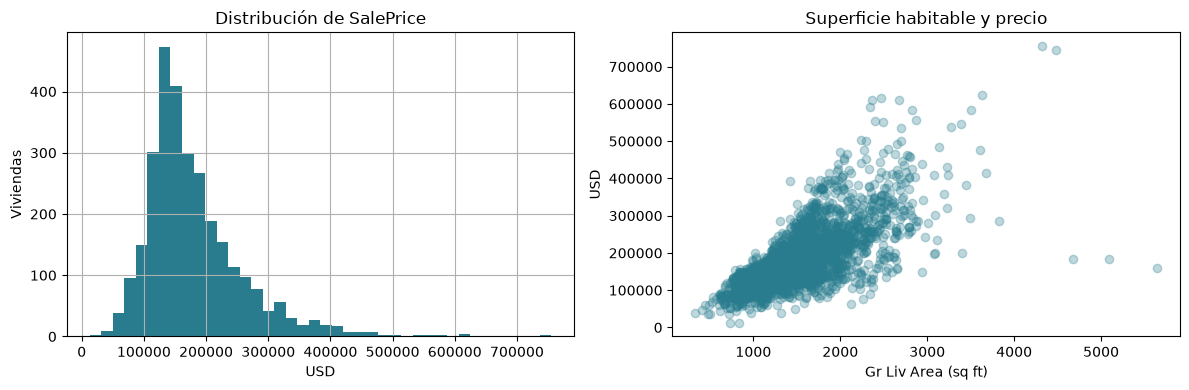

,spearman_saleprice
Overall Qual,0.808800
Gr Liv Area,0.723342
Garage Cars,0.701813
Year Built,0.680822
Garage Area,0.660676
Garage Yr Blt,0.637674
Full Bath,0.634161
Total Bsmt SF,0.606184
Year Remod/Add,0.601454
1st Flr SF,0.581536


In [3]:
missing_pct = (interim.isna().mean() * 100).sort_values(ascending=False)
quality = pd.DataFrame([{
    'filas_raw': len(raw), 'filas_interim': len(interim),
    'columnas_raw': raw.shape[1], 'duplicados_raw': int(raw.duplicated().sum()),
    'SalePrice_nulos_raw': int(raw['SalePrice'].isna().sum()),
    'precio_min_usd': interim['SalePrice'].min(),
    'precio_mediana_usd': interim['SalePrice'].median(),
    'precio_max_usd': interim['SalePrice'].max(),
}])
schema = pd.DataFrame({
    'tipo': interim.dtypes.astype(str).value_counts(),
    'cantidad_columnas': interim.dtypes.astype(str).value_counts(),
}).loc[:, ['cantidad_columnas']]
quality.to_csv(TABLES_DIR / '01_data_quality.csv', index=False)
missing_pct[missing_pct > 0].rename('faltantes_pct').to_csv(TABLES_DIR / '02_missing_values.csv')
display(quality)
display(schema)
display(missing_pct[missing_pct > 0].head(10).rename('faltantes_pct').to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
interim['SalePrice'].hist(bins=40, ax=axes[0], color='#287c8e')
axes[0].set(title='Distribución de SalePrice', xlabel='USD', ylabel='Viviendas')
axes[1].scatter(interim['Gr Liv Area'], interim['SalePrice'], alpha=.30, color='#287c8e')
axes[1].set(title='Superficie habitable y precio', xlabel='Gr Liv Area (sq ft)', ylabel='USD')
fig.tight_layout()
fig.savefig(FIGURES_DIR / '01_eda_price_area.png', dpi=160, bbox_inches='tight')
plt.show()

correlations = (interim.select_dtypes(include=np.number).corr(method='spearman')['SalePrice']
                .drop('SalePrice').sort_values(key=abs, ascending=False))
top_correlations = correlations.head(10).rename('spearman_saleprice').to_frame()
top_correlations.to_csv(TABLES_DIR / '03_top_numeric_associations.csv')
display(top_correlations)

### Hallazgos de EDA

`SalePrice` presenta dispersión y una cola hacia precios altos, por lo que RMSE complementa al MAE al señalar errores importantes. Las variables de calidad general, superficie habitable, capacidad de garaje y año de construcción muestran asociaciones altas con el precio. Los nulos se concentran en características poco frecuentes; por ello se imputan dentro del flujo de entrenamiento en lugar de eliminarlos indiscriminadamente.

## 3. Preparación y transformación de datos

El proyecto usa tres capas: `raw` conserva el archivo original; `interim` aplica validación de objetivo y duplicados; `processed` elimina los identificadores `Order` y `PID` antes del modelamiento.

Los nulos permanecen en `processed`. En cada pipeline, las columnas numéricas se imputan con mediana y escalan; las categóricas se completan con `Sin dato` y codifican con one-hot. El ajuste ocurre solo en entrenamiento, evitando fuga de información hacia test.

In [4]:
X, y = split_features_target(processed)
preprocessor = build_preprocessor(X)
feature_summary = pd.DataFrame([{
    'observaciones': len(X),
    'predictores': X.shape[1],
    'numericos': X.select_dtypes(include=np.number).shape[1],
    'categoricos': X.select_dtypes(exclude=np.number).shape[1],
    'ids_en_processed': ', '.join(c for c in ['Order', 'PID'] if c in processed.columns) or 'ninguno',
}])
display(feature_summary)
display(processed.head(3))
print('Transformadores configurados:', [name for name, _, _ in preprocessor.transformers])

,observaciones,predictores,numericos,categoricos,ids_en_processed
0,2930,79,36,43,ninguno


,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000


Transformadores configurados: ['numeric', 'categorical']


## 4. Modelamiento supervisado

Se reserva un **20% para test** y el **80% restante** para entrenar y seleccionar el modelo. Dentro del conjunto de entrenamiento se comparan Ridge, árbol de decisión y Random Forest mediante **validación cruzada de 5 particiones**, usando el RMSE promedio como criterio. La imputación, el escalamiento y la codificación están dentro de cada pipeline, por lo que se ajustan nuevamente en cada partición sin filtrar información de validación. La baseline de mediana se conserva como referencia. Una vez elegido el modelo, se evalúa en el test reservado, que no participa en la selección.

Ridge es una referencia lineal regularizada; el árbol modela reglas no lineales; Random Forest combina múltiples árboles para reducir la variabilidad.

,Modelo,CV_RMSE_USD,CV_RMSE_std_USD,MAE_USD,RMSE_USD,R2
0,Random Forest,26373.0,5500.0,15670.0,26572.0,0.912
1,Ridge,29657.0,9504.0,NaN,NaN,NaN
2,Árbol de decisión,38228.0,4904.0,NaN,NaN,NaN
3,Baseline mediana,NaN,NaN,63838.0,94323.0,-0.110


Modelo elegido por RMSE promedio de validación cruzada: Random Forest.
Evaluación final en test: RMSE $26,572; mejora de 71.8% frente a la baseline.


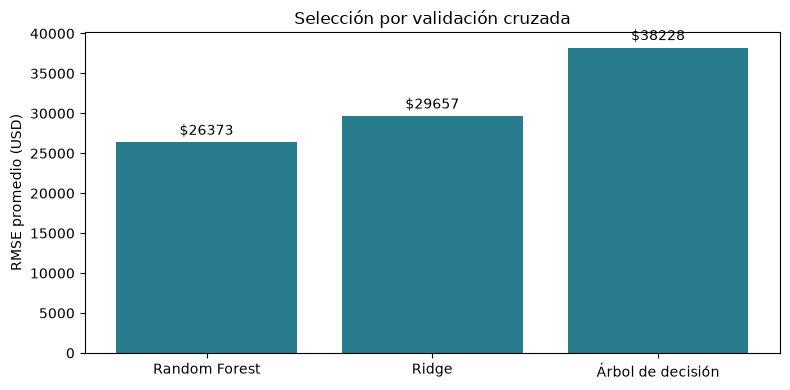

In [5]:
evaluation = evaluate_models(X, y)
metrics = evaluation['metrics']
best_name, best_model = evaluation['best_name'], evaluation['best_model']
X_test, y_test = evaluation['X_test'], evaluation['y_test']
metrics.to_csv(METRICS_DIR / 'model_metrics.csv', index=False)
display(metrics.round({'CV_RMSE_USD': 0, 'CV_RMSE_std_USD': 0, 'MAE_USD': 0, 'RMSE_USD': 0, 'R2': 3}))

baseline_rmse = metrics.loc[metrics['Modelo'].eq('Baseline mediana'), 'RMSE_USD'].iloc[0]
winner_rmse = metrics.loc[metrics['Modelo'].eq(best_name), 'RMSE_USD'].iloc[0]
improvement = (1 - winner_rmse / baseline_rmse) * 100
print(f'Modelo elegido por RMSE promedio de validación cruzada: {best_name}.')
print(f"Evaluación final en test: RMSE ${winner_rmse:,.0f}; mejora de {improvement:.1f}% frente a la baseline.")

plot_metrics = metrics.dropna(subset=['CV_RMSE_USD']).sort_values('CV_RMSE_USD')
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(plot_metrics['Modelo'], plot_metrics['CV_RMSE_USD'], color='#287c8e')
ax.set(title='Selección por validación cruzada', ylabel='RMSE promedio (USD)')
ax.bar_label(bars, fmt='$%.0f', padding=3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / '02_model_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

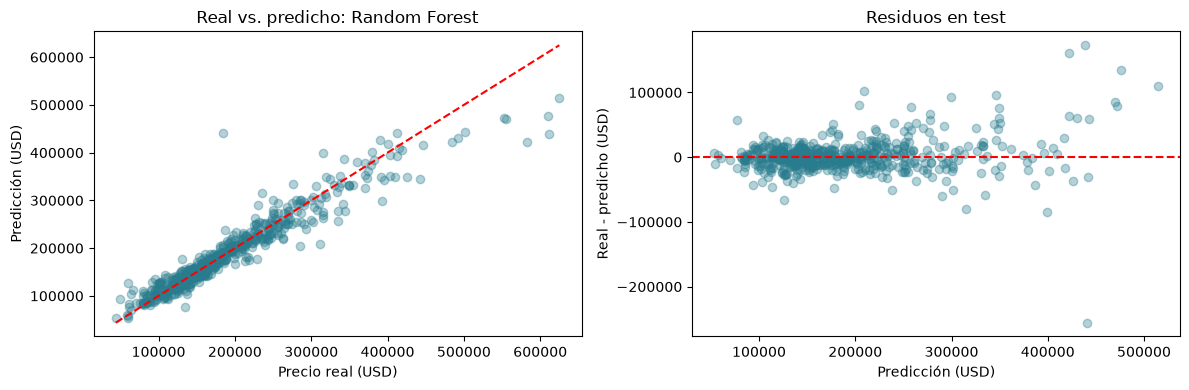

,viviendas,mae_usd
Barrio,,
NridgHt,45,33822.0
Edwards,44,19912.0
Somerst,46,14060.0
OldTown,40,12906.0
NWAmes,22,12787.0
CollgCr,56,12452.0
IDOTRR,20,12402.0
BrkSide,24,10107.0
SawyerW,27,10016.0


In [6]:
predictions = best_model.predict(X_test)
residuals = y_test.to_numpy() - predictions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
limit = [min(y_test.min(), predictions.min()), max(y_test.max(), predictions.max())]
axes[0].scatter(y_test, predictions, alpha=.35, color='#287c8e')
axes[0].plot(limit, limit, 'r--')
axes[0].set(title=f'Real vs. predicho: {best_name}', xlabel='Precio real (USD)', ylabel='Predicción (USD)')
axes[1].scatter(predictions, residuals, alpha=.35, color='#287c8e')
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set(title='Residuos en test', xlabel='Predicción (USD)', ylabel='Real - predicho (USD)')
fig.tight_layout()
fig.savefig(FIGURES_DIR / '03_test_predictions_residuals.png', dpi=160, bbox_inches='tight')
plt.show()

neighborhood_mae = pd.DataFrame({'Barrio': X_test['Neighborhood'].to_numpy(), 'error_abs_usd': np.abs(residuals)}).groupby('Barrio').agg(viviendas=('error_abs_usd', 'size'), mae_usd=('error_abs_usd', 'mean'))
display(neighborhood_mae.query('viviendas >= 20').sort_values('mae_usd', ascending=False).round({'mae_usd': 0}))

### Interpretación del desempeño y recomendación

El RMSE promedio de validación cruzada se usa para seleccionar entre los modelos candidatos; no es una métrica del test. El **MAE**, **RMSE** y **R²** que se muestran para el modelo elegido corresponden a la evaluación final en el test reservado. El MAE expresa el error absoluto promedio en dólares; el RMSE da más peso a errores grandes, y R² resume la proporción de variación del precio explicada.

Se recomienda usar el modelo ganador como apoyo de priorización y revisar manualmente predicciones con residuos altos. El diagnóstico por barrio es exploratorio: una diferencia de MAE identifica dónde revisar datos y desempeño, pero no demuestra por sí sola sesgo ni causalidad.

## 5. Aprendizaje no supervisado: perfiles de viviendas

K-means permite descubrir tipos de vivienda que ayudan a buscar comparables y organizar análisis comercial. Se agrupan ocho atributos físicos estandarizados. `SalePrice` queda fuera de la formación de clusters y se usa después solo para describir cada perfil; así los segmentos no se construyen a partir del precio objetivo.

,k,inercia,silhouette
0,2,16333.0,0.315
1,3,14571.0,0.303
2,4,13105.0,0.299
3,5,11769.0,0.233
4,6,10719.0,0.215


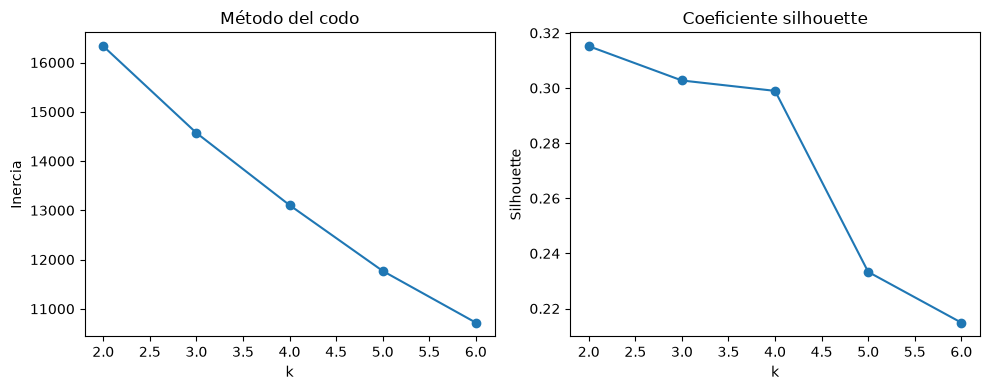

k seleccionado: 2 | silhouette: 0.315


,Cluster,viviendas,precio_mediano_usd,superficie_mediana,calidad_mediana,anio_construccion_mediano
0,0,1439,212000.0,1694.0,7.0,2000.0
1,1,1491,131000.0,1142.0,5.0,1956.0


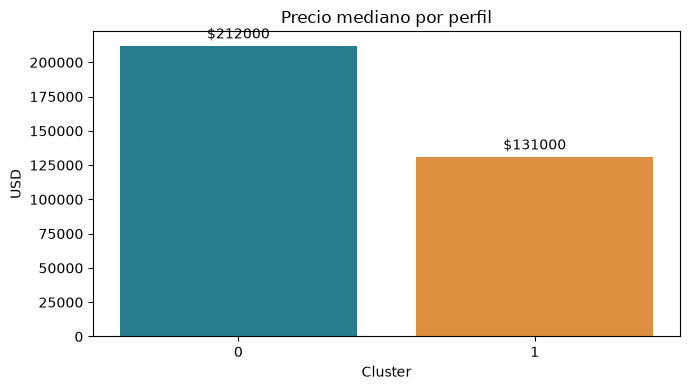

In [7]:
cluster_features = [c for c in CLUSTER_FEATURES if c in interim.columns]
cluster_values = SimpleImputer(strategy='median').fit_transform(interim[cluster_features])
cluster_X = StandardScaler().fit_transform(cluster_values)
rows = []
for k in range(2, 7):
    candidate = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(cluster_X)
    rows.append({'k': k, 'inercia': candidate.inertia_, 'silhouette': silhouette_score(cluster_X, candidate.labels_)})
k_selection = pd.DataFrame(rows)
k_selection.to_csv(TABLES_DIR / '04_kmeans_selection.csv', index=False)
display(k_selection.round({'inercia': 0, 'silhouette': 3}))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(k_selection['k'], k_selection['inercia'], marker='o')
axes[0].set(title='Método del codo', xlabel='k', ylabel='Inercia')
axes[1].plot(k_selection['k'], k_selection['silhouette'], marker='o')
axes[1].set(title='Coeficiente silhouette', xlabel='k', ylabel='Silhouette')
fig.tight_layout()
fig.savefig(FIGURES_DIR / '04_kmeans_selection.png', dpi=160, bbox_inches='tight')
plt.show()

selected_k = int(k_selection.loc[k_selection['silhouette'].idxmax(), 'k'])
segmented, silhouette, used_cluster_features = cluster_homes(interim, n_clusters=selected_k)
profiles = segmented.groupby('Cluster').agg(
    viviendas=('SalePrice', 'size'), precio_mediano_usd=('SalePrice', 'median'),
    superficie_mediana=('Gr Liv Area', 'median'), calidad_mediana=('Overall Qual', 'median'),
    anio_construccion_mediano=('Year Built', 'median'),
).reset_index()
profiles.to_csv(TABLES_DIR / '05_cluster_profiles.csv', index=False)
print(f'k seleccionado: {selected_k} | silhouette: {silhouette:.3f}')
display(profiles.round({'precio_mediano_usd': 0, 'superficie_mediana': 0, 'anio_construccion_mediano': 0}))

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(profiles['Cluster'].astype(str), profiles['precio_mediano_usd'], color=['#287c8e', '#de8f3f', '#7b5ea7', '#6c9f43', '#b34c6e'][:selected_k])
ax.set(title='Precio mediano por perfil', xlabel='Cluster', ylabel='USD')
ax.bar_label(bars, fmt='$%.0f', padding=3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / '05_cluster_profiles.png', dpi=160, bbox_inches='tight')
plt.show()

### Interpretación de los perfiles

Se selecciona el valor de `k` con mayor silhouette dentro del rango probado y se contrasta con la inercia. Los perfiles resumen viviendas con características físicas similares: tamaño, calidad, antigüedad y precio mediano posterior. Para el negocio, permiten buscar comparables dentro de un perfil antes de revisar una tasación individual.

Un silhouette moderado significa que los perfiles son útiles como descripción exploratoria, aunque sus fronteras no son perfectas. No deben reemplazar la estimación supervisada ni convertirse en reglas automáticas de precio.

## 6. Evaluación final, ética y uso

La solución se evalúa con datos de test nunca usados al ajustar los transformadores ni los modelos. El conjunto es histórico y corresponde a una sola ciudad; no representa precios actuales ni otras zonas. Variables de ubicación pueden reflejar condiciones socioeconómicas, por lo que el modelo no se debe usar para crédito, acceso a vivienda ni fijación automática de precios sin validación adicional y revisión humana.

In [8]:
save_final_artifacts(X, y, best_name)
summary = {
    'best_model': best_name, 'random_state': RANDOM_STATE, 'test_size': 0.20,
    'rows': len(processed), 'predictors': X.shape[1],
    'selected_k': selected_k, 'silhouette': float(silhouette),
}
(METRICS_DIR / 'run_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('Evidencias creadas:')
print('  Datos: data/interim/ames_validated.csv y data/processed/ames_modeling.csv')
print('  Modelos: models/preprocessor.joblib y models/best_model.joblib')
print('  Resultados: reports/figures, reports/metrics y reports/tables')

Evidencias creadas:
  Datos: data/interim/ames_validated.csv y data/processed/ames_modeling.csv
  Modelos: models/preprocessor.joblib y models/best_model.joblib
  Resultados: reports/figures, reports/metrics y reports/tables
